GPAW STANDARD DEVIATIONS
------------------------
Extrapolated energy: 0.14823 eV
Free energy: 0.14728 eV
Maximum force: 1.00875 eV/Angstrom

IBM QUANTUM ACCURACY
--------------------
H2O Expected: -74.964195 IBM: -74.783026 Absolute error: 181.17 mHa
H2 Expected: -1.13727 IBM: -0.932487 Absolute error: 204.783 mHa
O Expected: -73.709261 IBM: -73.521571 Absolute error: 187.69 mHa

Average IBM absolute error: 191.214 mHa


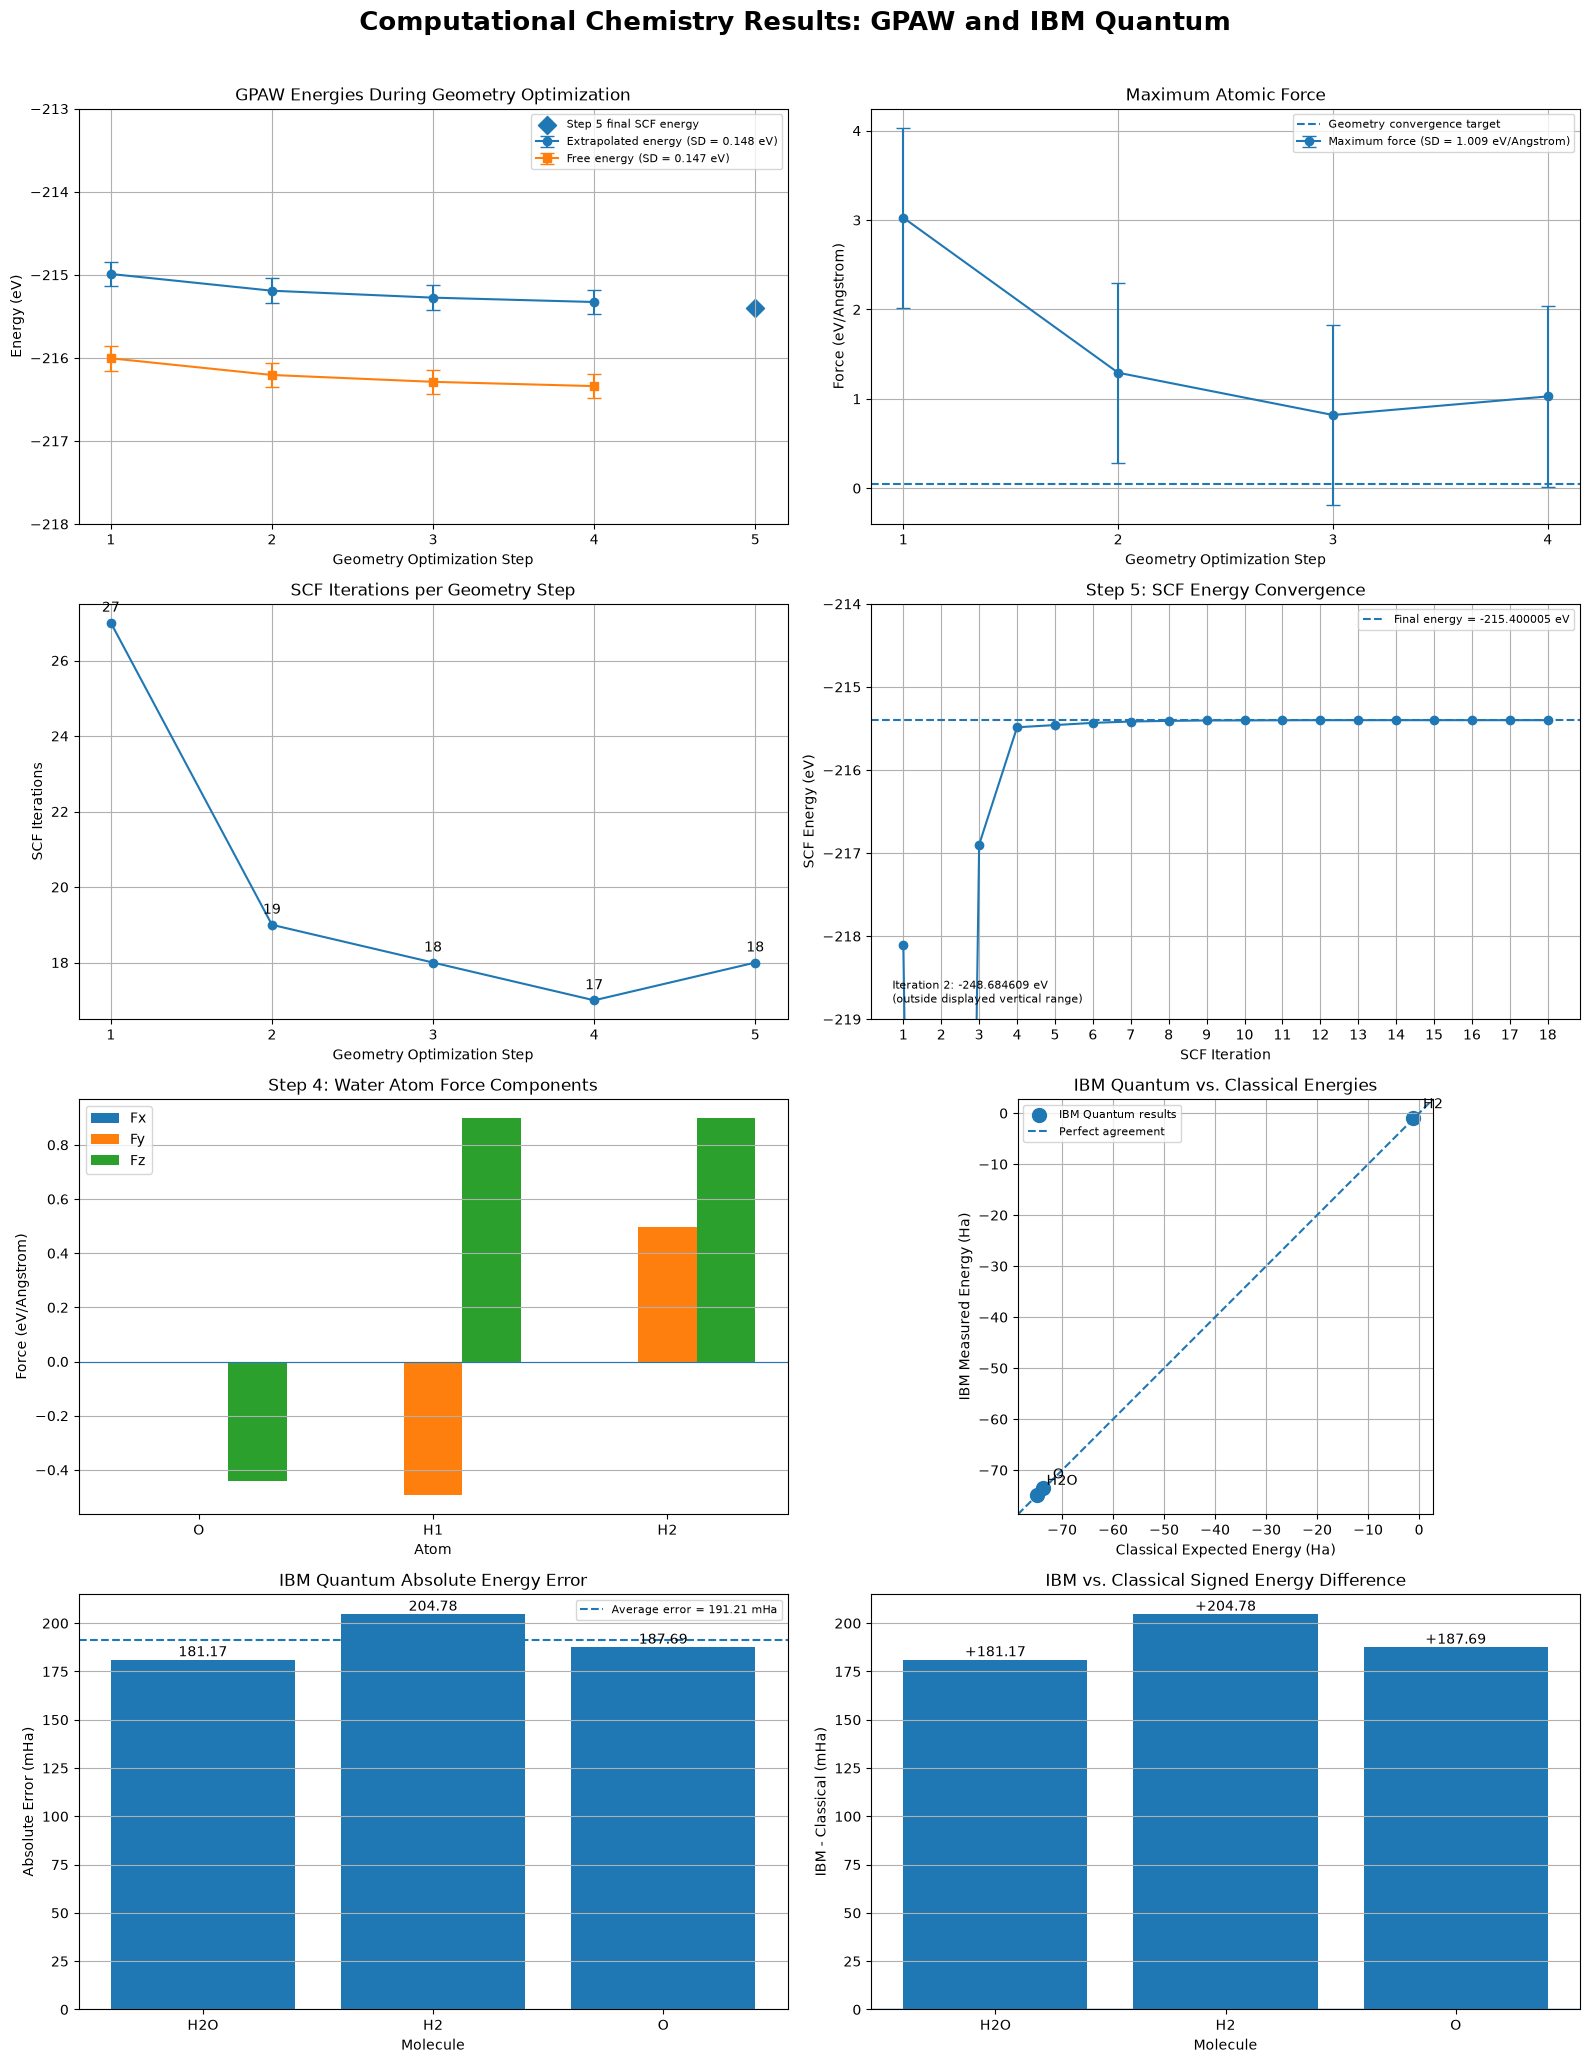


Combined graph saved as:
Complete_Quantum_and_GPAW_Results.png


In [6]:

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# 1. GPAW DATA: Pt(111) + H2O
# =====================================================

# Completed geometry optimization steps
steps = np.array([1, 2, 3, 4])

# Extrapolated energies (eV)
extrapolated_energy = np.array([
    -214.989594,
    -215.191074,
    -215.274414,
    -215.326921
])

# Free energies (eV)
free_energy = np.array([
    -216.004564,
    -216.205468,
    -216.287919,
    -216.339538
])

# SCF iterations per geometry step
scf_iterations = np.array([27, 19, 18, 17, 18])

# Maximum forces for the first four geometry steps
max_force = np.array([
    3.026,
    1.292,
    0.819,
    1.027
])

# Fifth geometry step: final SCF energy
step5_final_energy = -215.400005

# Fifth geometry step: all 18 SCF energies
step5_iterations = np.arange(1, 19)

step5_energy = np.array([
    -218.103567,
    -248.684609,
    -216.897664,
    -215.485684,
    -215.459050,
    -215.432670,
    -215.416406,
    -215.408537,
    -215.403404,
    -215.402737,
    -215.400955,
    -215.400151,
    -215.399986,
    -215.400019,
    -215.399979,
    -215.400019,
    -215.400012,
    -215.400005
])

# Step 4 force components for water atoms (eV/Angstrom)
atom_labels = ["O", "H1", "H2"]

fx = np.array([0.00000, 0.00000, 0.00000])
fy = np.array([-0.00242, -0.49435, 0.49590])
fz = np.array([-0.44023, 0.89845, 0.89959])


# =====================================================
# 2. IBM QUANTUM AND CLASSICAL DATA
# =====================================================

molecules = ["H2O", "H2", "O"]

# Classical active-space exact energies (Hartree)
expected_energy = np.array([
    -74.96419529199743,
    -1.1372701746609013,
    -73.70926134301918
])

# Original IBM Quantum hardware energies (Hartree)
measured_energy = np.array([
    -74.78302572385745,
    -0.9324872855541181,
    -73.52157142492591
])

# Energy differences
signed_error = measured_energy - expected_energy

# Convert Hartree differences to millihartrees
signed_error_mHa = signed_error * 1000
absolute_error_mHa = np.abs(signed_error_mHa)

average_error_mHa = np.mean(absolute_error_mHa)


# =====================================================
# 3. CALCULATE STANDARD DEVIATIONS
# =====================================================

# GPAW standard deviations across the four completed
# geometry optimization steps only.
extrapolated_std = np.std(extrapolated_energy, ddof=1)
free_energy_std = np.std(free_energy, ddof=1)
force_std = np.std(max_force, ddof=1)

print("GPAW STANDARD DEVIATIONS")
print("------------------------")
print("Extrapolated energy:", round(extrapolated_std, 5), "eV")
print("Free energy:", round(free_energy_std, 5), "eV")
print("Maximum force:", round(force_std, 5), "eV/Angstrom")

print("\nIBM QUANTUM ACCURACY")
print("--------------------")

for i in range(len(molecules)):
    print(
        molecules[i],
        "Expected:", round(expected_energy[i], 6),
        "IBM:", round(measured_energy[i], 6),
        "Absolute error:", round(absolute_error_mHa[i], 3), "mHa"
    )

print("\nAverage IBM absolute error:",
      round(average_error_mHa, 3), "mHa")


# =====================================================
# 4. CREATE ONE COMBINED IMAGE
# =====================================================

fig, axes = plt.subplots(4, 2, figsize=(16, 21))

fig.suptitle(
    "Computational Chemistry Results: GPAW and IBM Quantum",
    fontsize=19,
    fontweight="bold"
)


# =====================================================
# GRAPH 1: GPAW ENERGIES AND STANDARD DEVIATIONS
# =====================================================

ax = axes[0, 0]

ax.errorbar(
    steps,
    extrapolated_energy,
    yerr=extrapolated_std,
    marker="o",
    capsize=5,
    label=f"Extrapolated energy (SD = {extrapolated_std:.3f} eV)"
)

ax.errorbar(
    steps,
    free_energy,
    yerr=free_energy_std,
    marker="s",
    capsize=5,
    label=f"Free energy (SD = {free_energy_std:.3f} eV)"
)

# Fifth-step final SCF energy is shown separately because
# it is not confirmed to be an extrapolated or free energy.
ax.scatter(
    [5],
    [step5_final_energy],
    marker="D",
    s=85,
    label="Step 5 final SCF energy"
)

ax.set_ylim(-218, -213)

ax.set_title("GPAW Energies During Geometry Optimization")
ax.set_xlabel("Geometry Optimization Step")
ax.set_ylabel("Energy (eV)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(True)
ax.legend(fontsize=8)


# =====================================================
# GRAPH 2: MAXIMUM FORCE AND STANDARD DEVIATION
# =====================================================

ax = axes[0, 1]

ax.errorbar(
    steps,
    max_force,
    yerr=force_std,
    marker="o",
    capsize=5,
    label=f"Maximum force (SD = {force_std:.3f} eV/Angstrom)"
)

ax.axhline(
    0.05,
    linestyle="--",
    label="Geometry convergence target"
)

ax.set_title("Maximum Atomic Force")
ax.set_xlabel("Geometry Optimization Step")
ax.set_ylabel("Force (eV/Angstrom)")
ax.set_xticks(steps)
ax.grid(True)
ax.legend(fontsize=8)


# =====================================================
# GRAPH 3: SCF ITERATIONS PER GEOMETRY STEP
# =====================================================

ax = axes[1, 0]

geometry_steps = np.array([1, 2, 3, 4, 5])

ax.plot(
    geometry_steps,
    scf_iterations,
    marker="o"
)

for x, y in zip(geometry_steps, scf_iterations):
    ax.annotate(
        str(y),
        (x, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("SCF Iterations per Geometry Step")
ax.set_xlabel("Geometry Optimization Step")
ax.set_ylabel("SCF Iterations")
ax.set_xticks(geometry_steps)
ax.grid(True)


# =====================================================
# GRAPH 4: FIFTH STEP SCF ENERGY CONVERGENCE
# =====================================================

ax = axes[1, 1]

ax.plot(
    step5_iterations,
    step5_energy,
    marker="o"
)

# The second iteration is a large transient energy excursion.
# Restrict the displayed range to show the later stabilization.
ax.set_ylim(-219, -214)

ax.axhline(
    step5_final_energy,
    linestyle="--",
    label="Final energy = -215.400005 eV"
)

ax.set_title("Step 5: SCF Energy Convergence")
ax.set_xlabel("SCF Iteration")
ax.set_ylabel("SCF Energy (eV)")
ax.set_xticks(step5_iterations)
ax.grid(True)
ax.legend(fontsize=8)

ax.text(
    0.03,
    0.04,
    "Iteration 2: -248.684609 eV\n"
    "(outside displayed vertical range)",
    transform=ax.transAxes,
    fontsize=8
)


# =====================================================
# GRAPH 5: WATER ATOM FORCE COMPONENTS
# =====================================================

ax = axes[2, 0]

x = np.arange(len(atom_labels))
width = 0.25

ax.bar(x - width, fx, width, label="Fx")
ax.bar(x, fy, width, label="Fy")
ax.bar(x + width, fz, width, label="Fz")

ax.axhline(0, linewidth=0.8)

ax.set_title("Step 4: Water Atom Force Components")
ax.set_xlabel("Atom")
ax.set_ylabel("Force (eV/Angstrom)")
ax.set_xticks(x)
ax.set_xticklabels(atom_labels)
ax.grid(axis="y")
ax.legend()


# =====================================================
# GRAPH 6: CLASSICAL VS IBM QUANTUM ENERGY
# =====================================================

ax = axes[2, 1]

# Scatter plot with equal scales to show agreement.
ax.scatter(
    expected_energy,
    measured_energy,
    s=100,
    label="IBM Quantum results"
)

minimum = min(expected_energy.min(), measured_energy.min())
maximum = max(expected_energy.max(), measured_energy.max())

padding = (maximum - minimum) * 0.05

ax.plot(
    [minimum - padding, maximum + padding],
    [minimum - padding, maximum + padding],
    linestyle="--",
    label="Perfect agreement"
)

for i, molecule in enumerate(molecules):
    ax.annotate(
        molecule,
        (expected_energy[i], measured_energy[i]),
        xytext=(7, 7),
        textcoords="offset points"
    )

ax.set_title("IBM Quantum vs. Classical Energies")
ax.set_xlabel("Classical Expected Energy (Ha)")
ax.set_ylabel("IBM Measured Energy (Ha)")
ax.set_xlim(minimum - padding, maximum + padding)
ax.set_ylim(minimum - padding, maximum + padding)
ax.set_aspect("equal", adjustable="box")
ax.grid(True)
ax.legend(fontsize=8)


# =====================================================
# GRAPH 7: IBM QUANTUM ABSOLUTE ERROR
# =====================================================

ax = axes[3, 0]

bars = ax.bar(
    molecules,
    absolute_error_mHa
)

ax.axhline(
    average_error_mHa,
    linestyle="--",
    label=f"Average error = {average_error_mHa:.2f} mHa"
)

for bar, value in zip(bars, absolute_error_mHa):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

ax.set_title("IBM Quantum Absolute Energy Error")
ax.set_xlabel("Molecule")
ax.set_ylabel("Absolute Error (mHa)")
ax.grid(axis="y")
ax.legend(fontsize=8)


# =====================================================
# GRAPH 8: IBM QUANTUM SIGNED ENERGY DIFFERENCE
# =====================================================

ax = axes[3, 1]

bars = ax.bar(
    molecules,
    signed_error_mHa
)

ax.axhline(0, linewidth=1)

for bar, value in zip(bars, signed_error_mHa):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:+.2f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

ax.set_title("IBM vs. Classical Signed Energy Difference")
ax.set_xlabel("Molecule")
ax.set_ylabel("IBM - Classical (mHa)")
ax.grid(axis="y")


# =====================================================
# 5. FINAL FORMATTING AND SAVE
# =====================================================

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    "Complete_Quantum_and_GPAW_Results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCombined graph saved as:")
print("Complete_Quantum_and_GPAW_Results.png")
